## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

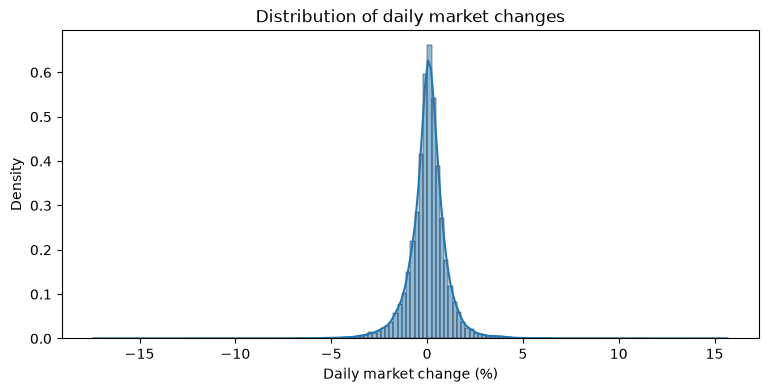

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

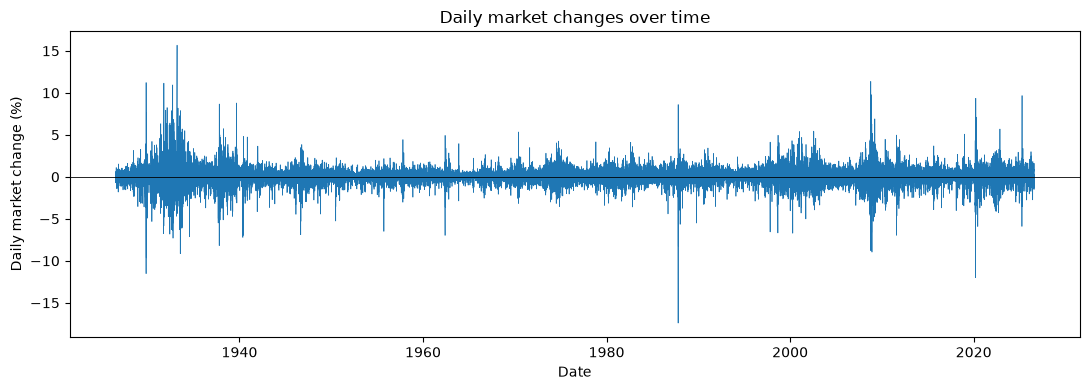

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# current and next day returns
df['today_return'] = df['market_return_pct'] # today
df['tomorrow_return'] = df['market_return_pct'].shift(-1) # next day

# dropping last row bc no next trading day
d1 = df.dropna(subset=['tomorrow_return']).copy()
d1.head(1)

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,today_return,tomorrow_return
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.1,0.1,0.1,0.46


In [5]:
# two state categories
d1['current_state'] = np.where(d1['today_return'] > 0, 'Up', 'Down')
d1['next_state'] = np.where(d1['tomorrow_return'] > 0, 'Up', 'Down')

In [6]:
# joint pmf with marginal probability
joint = pd.crosstab(d1['current_state'], d1['next_state'], normalize='all', margins=True)
print('joint pmf (rows = today, cols = tomorrow), with marginal probabilities')
print(joint.round(4))

joint pmf (rows = today, cols = tomorrow), with marginal probabilities
next_state       Down      Up     All
current_state                        
Down           0.2247  0.2281  0.4529
Up             0.2281  0.3190  0.5471
All            0.4529  0.5471  1.0000


In [7]:
# conditional pmf: P(tomorrow | today)
cond = pd.crosstab(d1['current_state'], d1['next_state'], normalize='index')
print('conditional PMF: P(tomorrow | today)')
print(cond.round(4))

conditional PMF: P(tomorrow | today)
next_state       Down      Up
current_state                
Down           0.4962  0.5038
Up             0.4170  0.5830


In [8]:
print(f"P(Up tomorrow)        = {joint.loc['All', 'Up']:.4f}")
print(f"P(Down tomorrow)      = {joint.loc['All', 'Down']:.4f}")
print(f"P(Up | today Up)      = {cond.loc['Up', 'Up']:.4f}")
print(f"P(Up | today Down)    = {cond.loc['Down', 'Up']:.4f}")

P(Up tomorrow)        = 0.5471
P(Down tomorrow)      = 0.4529
P(Up | today Up)      = 0.5830
P(Up | today Down)    = 0.5038


#### Are up transitions more or less common than down transitions? 

In [9]:
print(f"P(Up tomorrow) = {joint.loc['All', 'Up']:.4f}")
print(f"P(Down tomorrow) = {joint.loc['All', 'Down']:.4f}")

P(Up tomorrow) = 0.5471
P(Down tomorrow) = 0.4529


Up transitions have a probability 0.55 while down transitions have a probability of 0.45, so up transitions are more common.

#### Are you more likely to transition to an Up day from a Down or Up day?

In [10]:
print(f"P(Up | today Up)  = {cond.loc['Up', 'Up']:.4f}")
print(f"P(Up | today Down) = {cond.loc['Down', 'Up']:.4f}")

P(Up | today Up)  = 0.5830
P(Up | today Down) = 0.5038


You are more likely to transition to an up day from an up day, as that conditional probability is 0.58 while the conditional probability of going from an up day from a down day is 0.50.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [11]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

d1['today_bin'] = pd.cut(d1['today_return'], bins=bins, labels=labels)
d1['tomorrow_bin'] = pd.cut(d1['tomorrow_return'], bins=bins, labels=labels)

In [12]:
print(d1['today_bin'].value_counts(sort=False), '\n')

today_bin
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9784
Large gain    2859
Name: count, dtype: int64 



#### Compute the joint PMF and marginals. Which transitions are most likely to occur? 

In [13]:
# joint pmf with marginals
joint5 = pd.crosstab(d1['today_bin'], d1['tomorrow_bin'], normalize='all', margins=True)
print(joint5.round(4))

tomorrow_bin  Large loss  Small loss  Near zero  Small gain  Large gain  \
today_bin                                                                 
Large loss        0.0213      0.0272     0.0091      0.0278      0.0195   
Small loss        0.0354      0.0886     0.0342      0.0978      0.0274   
Near zero         0.0093      0.0420     0.0210      0.0493      0.0093   
Small gain        0.0250      0.1001     0.0550      0.1594      0.0326   
Large gain        0.0138      0.0255     0.0116      0.0378      0.0199   
All               0.1049      0.2834     0.1308      0.3721      0.1087   

tomorrow_bin     All  
today_bin             
Large loss    0.1049  
Small loss    0.2834  
Near zero     0.1309  
Small gain    0.3721  
Large gain    0.1087  
All           1.0000  


Small gains -> small gains are by far the most likely transitions to occur at a joint probability of 0.16, with small gains to small losses close behind at 0.10, and small losses to small losses trailing a bit further behind than that at 0.09.

#### Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

In [14]:
# conditional pmf
cond5 = pd.crosstab(d1['today_bin'], d1['tomorrow_bin'], normalize='index')
print(cond5.round(4))

tomorrow_bin  Large loss  Small loss  Near zero  Small gain  Large gain
today_bin                                                              
Large loss        0.2033      0.2592     0.0863      0.2650      0.1863
Small loss        0.1251      0.3128     0.1205      0.3450      0.0966
Near zero         0.0712      0.3208     0.1601      0.3769      0.0709
Small gain        0.0672      0.2689     0.1479      0.4285      0.0876
Large gain        0.1273      0.2347     0.1070      0.3477      0.1833


Current state: 

Large loss - small gain (0.27) and small loss (0.26)

Small loss - small gain (0.35) and small loss (0.31)

Near zero - small gain (0.38) and small loss (0.32)

Small gain - small gain (0.43) and small loss (0.27)

Large gain - small gain (0.35) and small loss (0.23)

None of the rows are uniform. Every row puts most of its mass on small gain and small loss, with values as high as 0.43 and as low as 0.07, but this is mostly because those bins are the most common overall. 

It is relatively difficult to predict the next state. The single most likely outcome is a small gain in every row, so the best guess does not change depending on the current state.


#### For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [15]:
d1.groupby('today_bin', observed=True)['tomorrow_return'].describe()

,count,mean,std,min,25%,50%,75%,max
today_bin,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


Tomorrow's expected return is close to zero in every state. It is about -0.04% for a large loss, -0.04% after a small loss, 0.02% on a near zero day, 0.11% after a small gain, and 0.16% after a large gain. Expected returns rise somewhat as today's state moves from losses to gains. These differences are tiny compared to the standard deviations, which run from 0.8 to 1.7. 

The range of tomorrow's return depends a lot on today's state. After a large loss, tomorrow ranged from -17.41% to 11.22% and after a large gain, from -12.00% to 15.67%. Extreme days, in either direction, tend to follow other large moves rather than calm days. 

Large loss has the largest standard deviation of tomorrow's returns (1.72), followed by large gain (1.38), and small loss (1.01). Near zero (0.83) and small gain (0.83) have the lowest.

Volatility is U-shaped. It is lowest after calm days and highest after large moves in either direction. This is volatility clustering. The pattern is asymmetric because losses lead to more volatility than gains of a similar size, since large loss (1.72) is larger thanlarge gain (1.38) and small loss (1.01) is higher than small gain (0.83).


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

#### Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 

In [16]:
df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)

d3 = df.dropna(subset=['y_tp1']).copy()
d3['y_tp1'] = d3['y_tp1'].astype(int)

print(d3['y_t'].value_counts().sort_index())

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1282
18    1225
19    1250
20    1238
Name: count, dtype: int64


#### Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

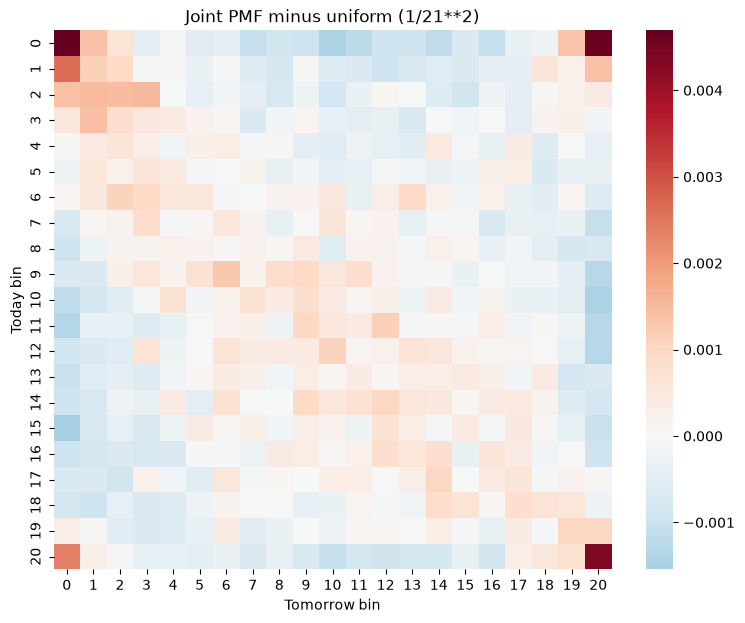

In [ ]:
# joint pmf heatmap with subtraction
joint21 = pd.crosstab(d3['y_t'], d3['y_tp1'], normalize='all')

fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(joint21 - 1/21**2, cmap='RdBu_r', center=0, ax=ax) #center=0 makes white mean “exactly uniform,” red mean “more than uniform,” and blue mean “less than uniform.”
ax.set(xlabel='Tomorrow bin', ylabel='Today bin',
       title='Joint PMF minus uniform (1/21**2)')
plt.show()

The joint PMF is mostly close to uniform, as most cells fall within ±0.0005 of 1/21<sup>2</sup>, so the typical pair of days is roughly as likely as any other pair. There are clear exceptions at the four corners. Pairs of extreme days, such as the worst folowed by the worst (0,0), worst followed by best (0, 20), and best followed by best (20,20) occur far more than the uniform rate.

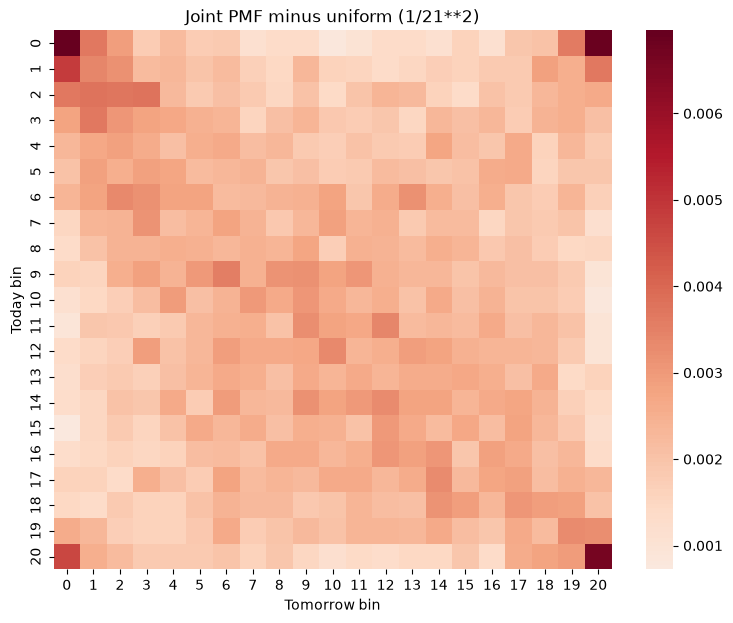

In [19]:
# joint pmf heatmap without subtraction
joint21 = pd.crosstab(d3['y_t'], d3['y_tp1'], normalize='all')

fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(joint21, cmap='RdBu_r', center=0, ax=ax) #center=0 makes white mean “exactly uniform,” red mean “more than uniform,” and blue mean “less than uniform.”
ax.set(xlabel='Tomorrow bin', ylabel='Today bin',
       title='Joint PMF minus uniform (1/21**2)')
plt.show()

 #### Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

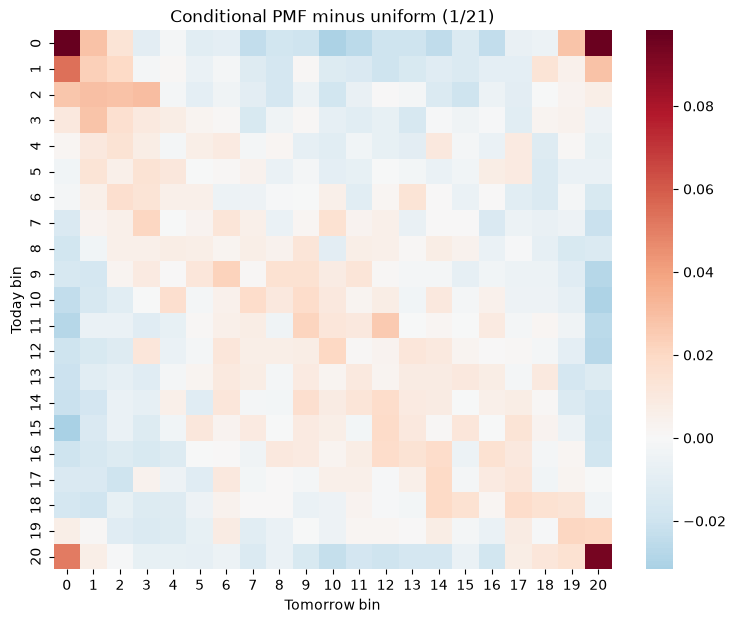

In [23]:
cond21 = pd.crosstab(d3['y_t'], d3['y_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cond21 - 1/21, cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Tomorrow bin', ylabel='Today bin',
       title='Conditional PMF minus uniform (1/21)')
plt.show()

The conditional PMF looks basically the same as the joint PMF. After a really bad or really good day, tomorrow is about two to three times more likely than normal to be another extreme day (red probabilities are about 0.9 - add uniform value (0.048) back and then divide by 0.048 = ~3 more likely), and it’s just as likely to be extremely good as extremely bad. After a normal day, tomorrow is usually normal too. Everything else is close to random. So today tells you whether tomorrow will be a big move, but not whether it will be up or down.


#### For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

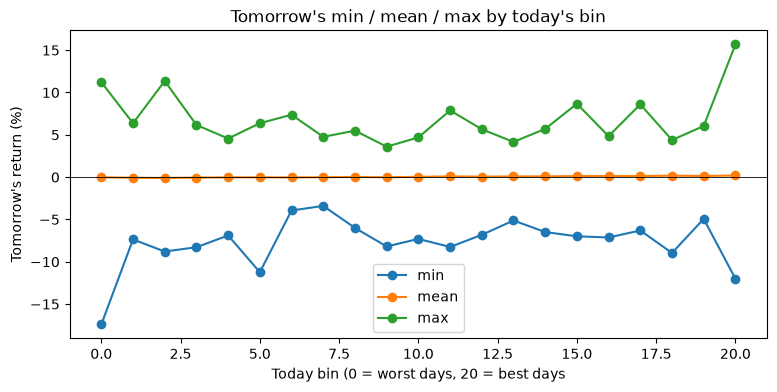

In [21]:
# next day min, mean, max by bin
stats21 = d3.groupby('y_t')['tomorrow_return'].agg(['min', 'mean', 'max', 'std'])

fig, ax = plt.subplots(figsize=(9,4))
for col in ['min', 'mean', 'max']:
    ax.plot(stats21.index, stats21[col], marker='o', label=col)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Today bin (0 = worst days, 20 = best days',
       ylabel="Tomorrow's return (%)", title="Tomorrow's min / mean / max by today's bin")
ax.legend()
plt.show()

The mean stays flat at about 0 across all 21 bins, so today's bin rarely changes tomorrow's expected return. The min and max change a lot more. They are farthest apart after the most extreme days: after a bin 0 day, tomorrow ranged from about -17% to about 11%, and after a bin 20 day, from about -12% to 16%. After middle bins, the range is usually narrower, around -4% to -8% on the low end and +4% to +8% on the high end. 

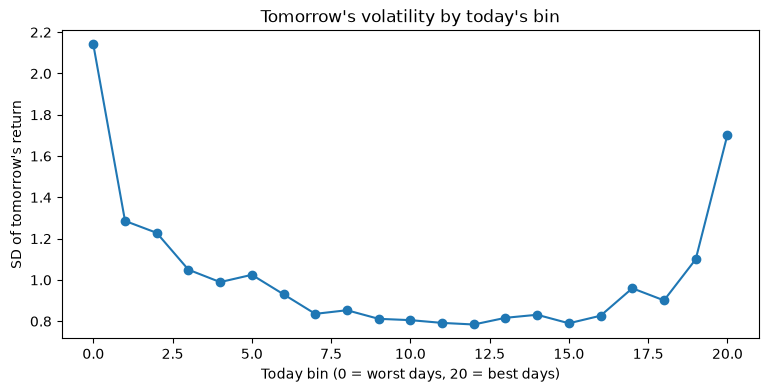

In [22]:
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(stats21.index, stats21['std'], marker='o')
ax.set(xlabel='Today bin (0 = worst days, 20 = best days)',
       ylabel="SD of tomorrow's return", title="Tomorrow's volatility by today's bin")
plt.show()

The standard deviation of tomorrow's return is clearly U-shaped. After a middle bin day (roughly bins 7-16), it stays flat at about 0.8. It rises sharply towards both ends reaching about 2.1 after the worst days (bin 0) and about 1.7 after the best days (bin 20). Tomorrow is far more volatile after an extreme day than a normal one. 